# Notebook 2 — Covariance and Correlation

Same café dataset. In Notebook 1 we *looked* at relationships; now we *measure* them.

**What you will learn**
1. **Covariance** — tells us the *direction* of a relationship, but its size depends on the units
2. **Pearson's correlation coefficient ($r$)** — a *standardised* measure from −1 to +1
3. The **limitations** of correlation: outliers and non-linear patterns

## Setup
Run this cell first (and again after restarting the kernel). It imports the libraries we need and loads
`cafe_daily.csv`, which must sit in the same folder as this notebook.

- **pandas / numpy** – tables and numerical work
- **matplotlib / seaborn** – plotting
- **scipy.stats** – correlation and regression helpers

`cafe.head()` shows the first five rows so you can check the data loaded correctly.
See `data_dictionary.md` for what every column means.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")

cafe = pd.read_csv("cafe_daily.csv", parse_dates=["date"])
cafe.head()

,date,day_of_week,is_weekend,temperature_c,iced_drink_sales,hot_drink_sales,cold_brew_sales,salad_sales,foot_traffic,barista_shoe_size,social_followers,promo_active,discount_pct,daily_revenue,daily_profit,pastry_demand
0,2024-01-01,Monday,0,2.0,30,168,11,8,229,41.5,499,1,15,817.78,850.41,70
1,2024-01-02,Tuesday,0,-0.2,25,191,7,14,216,43.0,503,0,35,881.36,560.69,57
2,2024-01-03,Wednesday,0,2.6,30,188,1,18,259,39.0,512,0,20,939.55,840.85,76
3,2024-01-04,Thursday,0,2.9,36,176,12,16,209,45.0,519,0,25,1031.60,780.45,60
4,2024-01-05,Friday,0,-1.8,13,176,2,0,218,42.5,520,1,15,795.42,857.18,65


## Part 1 — Understanding Positive and Negative Covariance

**Covariance** measures how two variables vary *together*:

$$\operatorname{cov}(x, y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})$$

**Where:**

| Symbol | Meaning |
|---|---|
| $\operatorname{cov}(x, y)$ | the **covariance** between $x$ and $y$ |
| $x_i,\ y_i$ | the values of the two variables on the same day $i$ (e.g. temperature and iced-drink sales) |
| $\bar{x},\ \bar{y}$ | the means of $x$ and $y$ |
| $x_i - \bar{x}$ | how far $x$ is above (+) or below (−) its mean on day $i$ |
| $y_i - \bar{y}$ | how far $y$ is above (+) or below (−) its mean on day $i$ |
| $(x_i - \bar{x})(y_i - \bar{y})$ | the product of the two deviations — positive when both move the same way |
| $\sum_{i=1}^{n}$ | add the products up over all days |
| $n$ | the number of days (paired observations) |
| $\frac{1}{n-1}$ | turns the total into an average (using $n-1$ for a sample) |


For each day we multiply "how far $x$ is from its mean" by "how far $y$ is from its mean":
- Both above average, or both below → the product is **positive**
- One above and one below → the product is **negative**

Averaging these products gives the covariance:

| Sign of cov | Meaning |
|---|---|
| $> 0$ | variables tend to move in the **same** direction |
| $< 0$ | variables tend to move in **opposite** directions |
| $\approx 0$ | no consistent linear co-movement |

**The catch:** covariance is measured in *units of x × units of y* (e.g. °C × drinks). Its size changes
if you change the units (°C → °F), so you cannot compare covariances between different pairs to decide which is "stronger".

`np.cov(a, b)` returns a 2×2 matrix; the element `[0, 1]` is $\operatorname{cov}(a, b)$.

In [2]:
pairs = [('temperature_c','iced_drink_sales'),
         ('temperature_c','hot_drink_sales'),
         ('barista_shoe_size','daily_revenue')]
for a,b in pairs:
    print(f'cov({a}, {b}) = {np.cov(cafe[a], cafe[b])[0,1]:9.2f}')

cov(temperature_c, iced_drink_sales) =    280.54
cov(temperature_c, hot_drink_sales) =   -204.63
cov(barista_shoe_size, daily_revenue) =      1.71


**Interpreting the output**
- Temperature & iced drinks: positive (≈ +281) → they rise together.
- Temperature & hot drinks: negative (≈ −205) → as temperature rises, hot-drink sales fall.
- Shoe size & revenue: small (≈ +1.7) — but is that "small"? Revenue is measured in euros and can be large,
  so it is hard to judge from the raw number. This is exactly why we standardise.

## Part 2 — The Pearson Correlation Coefficient

Pearson's $r$ is covariance divided by the two standard deviations, which removes the units:

$$r = \frac{\operatorname{cov}(x, y)}{s_x\, s_y} = \frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\;\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}$$

where $s_x = \sqrt{\frac{1}{n-1}\sum (x_i-\bar{x})^2}$ is the standard deviation of $x$ (likewise $s_y$).

**Where:**

| Symbol | Meaning |
|---|---|
| $r$ | **Pearson's correlation coefficient**, always between −1 and +1 |
| $\operatorname{cov}(x, y)$ | the covariance from Part 1 |
| $s_x,\ s_y$ | the **standard deviations** of $x$ and $y$ (how spread out each variable is) |
| $x_i,\ y_i$ | the paired values on day $i$ |
| $\bar{x},\ \bar{y}$ | the means of $x$ and $y$ |
| $n$ | the number of paired observations |
| $\sum$ | sum over all observations |
| $r^2$ | the **coefficient of determination** — the share (0 to 1) of the variation in $y$ explained by a straight line in $x$ |


Properties:
- $-1 \le r \le +1$, and it has **no units** — so different pairs *can* be compared
- $r = +1$: perfect positive straight line; $r = -1$: perfect negative straight line; $r = 0$: no *linear* relationship
- $r$ is symmetric: $r(x, y) = r(y, x)$

A common rule of thumb for $|r|$ (it depends on the field):

| $\lvert r \rvert$ | Strength |
|---|---|
| 0.0 – 0.1 | none / negligible |
| 0.1 – 0.3 | weak |
| 0.3 – 0.7 | moderate |
| 0.7 – 1.0 | strong |

**$r^2$ (coefficient of determination)** is the share of the variation in $y$ that a straight line in $x$ explains.
For example $r = 0.9 \Rightarrow r^2 = 0.81$, i.e. about 81 %.

`stats.pearsonr` returns $r$ and a p-value (the p-value tests whether $r$ could plausibly be 0; we only print $r$ here).

In [3]:
for a,b in pairs:
    r, p = stats.pearsonr(cafe[a], cafe[b])
    print(f'r({a}, {b}) = {r:+.3f}')

r(temperature_c, iced_drink_sales) = +0.902
r(temperature_c, hot_drink_sales) = -0.908
r(barista_shoe_size, daily_revenue) = +0.003


**Interpreting the output**
- $r \approx +0.90$: strong positive — temperature and iced drinks
- $r \approx -0.91$: strong negative — temperature and hot drinks
- $r \approx 0.00$: no linear relationship — shoe size and revenue

Notice how the two temperature pairs now have almost the same *strength*, which was impossible to see from the covariances.

Next, a **correlation matrix**: $r$ for every pair of numeric columns at once. The diagonal is always 1
(each variable correlates perfectly with itself) and the matrix is symmetric. It is a handy way to
communicate many relationships in one picture. (`is_weekend` and `promo_active` are 0/1 flags, so we leave them out.)

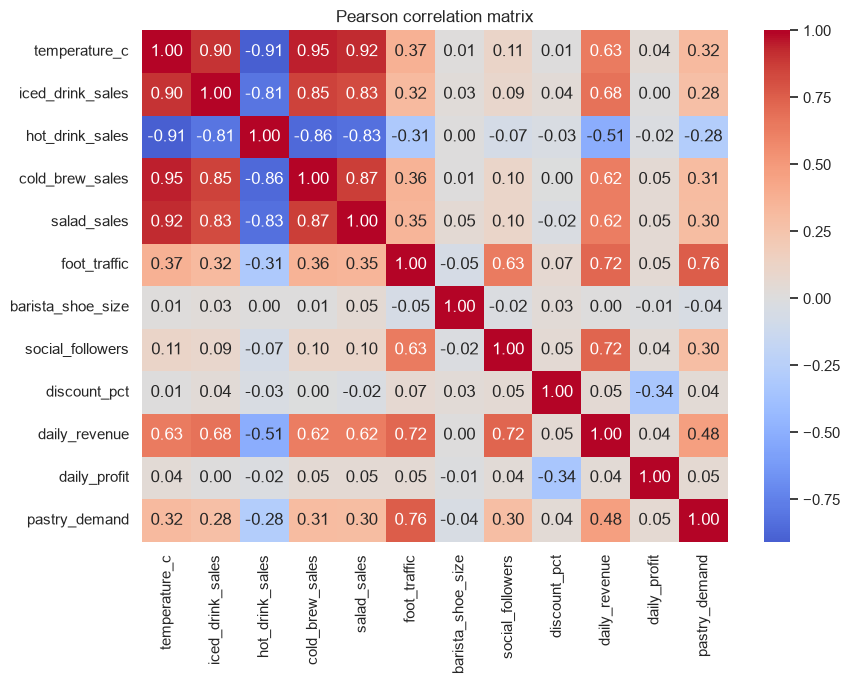

In [4]:
# Full correlation matrix as a communication tool
num = cafe.select_dtypes('number').drop(columns=['is_weekend','promo_active'])
plt.figure(figsize=(9,7))
sns.heatmap(num.corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Pearson correlation matrix'); plt.tight_layout(); plt.show()

## Part 3 — Limitations of Correlation

Pearson's $r$ is useful, but it has two big blind spots:

**(a) Outliers.** Because $r$ is built from squared distances from the mean, a single extreme point can pull it
up or down a lot. We compare $r$ with and without the one-off catering day from Notebook 1.

In [5]:
# (a) Outlier sensitivity — drop the one-off catering day and watch r change
r_all,  _ = stats.pearsonr(cafe['temperature_c'], cafe['iced_drink_sales'])
no_out  = cafe.drop(cafe['iced_drink_sales'].idxmax())
r_clean,_ = stats.pearsonr(no_out['temperature_c'], no_out['iced_drink_sales'])
print(f'r with outlier   : {r_all:+.3f}')
print(f'r without outlier: {r_clean:+.3f}')

r with outlier   : +0.902
r without outlier: +0.955


Removing **one** day out of 731 moves $r$ from about **0.90** to about **0.95**. One unusual point was hiding
how strong the real temperature relationship is. Always check for outliers — and decide, with a good reason,
whether they belong in the analysis.

**(b) Non-linearity.** Pearson only measures *straight-line* relationships. Discount vs profit follows an
inverted U, roughly

$$\text{profit} \approx a + b \cdot \text{discount} - c \cdot \text{discount}^2 \quad (c > 0)$$

**Where:**

| Symbol | Meaning |
|---|---|
| $\text{profit}$ | daily profit in € (`daily_profit`) — the outcome |
| $\text{discount}$ | the discount percentage applied that day (`discount_pct`, 0–40) |
| $\text{discount}^2$ | the discount squared — this term is what bends the line into a curve |
| $a$ | the baseline profit when there is no discount |
| $b$ | the upward effect of discounting (more customers) — dominates at small discounts |
| $c$ | how strongly profit falls at large discounts (lost margin); $c > 0$ makes the curve open downwards (∩) |


so profit rises for small discounts and falls for large ones. The red line shows the average profit at each discount level.

Pearson r(discount, profit) = -0.339  <- misleadingly weak


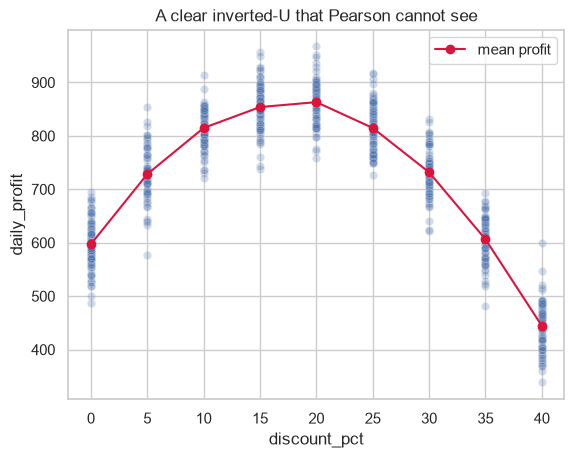

In [6]:
# (b) Non-linearity — Pearson looks weak, but the shape is strong
r,_ = stats.pearsonr(cafe['discount_pct'], cafe['daily_profit'])
print(f'Pearson r(discount, profit) = {r:+.3f}  <- misleadingly weak')
means = cafe.groupby('discount_pct')['daily_profit'].mean()
sns.scatterplot(data=cafe, x='discount_pct', y='daily_profit', alpha=.25)
plt.plot(means.index, means.values, 'o-', color='crimson', label='mean profit')
plt.legend(); plt.title('A clear inverted-U that Pearson cannot see'); plt.show()

Pearson gives only $r \approx -0.34$, which suggests a weak relationship — yet the plot shows a **strong, clear
curve**. The upward half and the downward half partly cancel out, so a straight-line measure misses most of the pattern.

*(Going further: rank-based measures like Spearman's $\rho$ handle monotonic curves, but not a U-shape like this one —
plotting is still the best check.)*

### Key takeaways
- **Covariance** gives the *direction*; its size depends on units.
- **Pearson's $r$** = covariance ÷ (std x · std y): unit-free, between −1 and +1, comparable across pairs.
- $r$ only measures **linear** relationships and is **sensitive to outliers** — always plot your data.